In [27]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm
from matplotlib.ticker import PercentFormatter, FuncFormatter
import glob
from concurrent.futures import ProcessPoolExecutor
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader
from tensorboard.util import tensor_util
from tb_loader import load_file
from scipy.stats import ttest_ind, false_discovery_control
from matplotlib.patches import Ellipse
from typing import Literal

In [28]:
IMPORTANT_STATS_NAMES = {
    "reward/mean": "Reward per timestep",
    "observation/progress_per_second": "PPS",
    "observation/forward_velocity": "Forward velocity",
    "collision/per_progress_metres": "CPMP",
    "collision/per_episode": "Collisions per episode",
    "collision/per_step": "Collisions per step",
    "observation/progress_metres": "Progress metres"
}

IMPORTANT_STATS = [key for key in IMPORTANT_STATS_NAMES.keys()]

MOST_IMPORTANT_STATS = [
    "reward/mean",
    "observation/progress_per_second",
    "collision/per_progress_metres"
]

MOST_IMPORTANT_STATS_NAMES = {key: IMPORTANT_STATS_NAMES[key] for key in MOST_IMPORTANT_STATS}

In [29]:
def load_runs(logdir="runs", tags=None):
    tags = set(tags) if tags is not None else None
    jobs = []
    for model_name in os.listdir(logdir):
      for f in sorted(glob.glob(f"{logdir}/{model_name}/**/*tfevents*", recursive=True)):
          jobs.append((f, model_name, tags))

    with ProcessPoolExecutor() as pool:
        return pd.concat(pool.map(load_file, jobs), ignore_index=True)
                                 # all tags
if os.path.exists("results/tensorboard_data.pkl"):
    df = pd.read_pickle("results/tensorboard_data.pkl")
else:
    df = load_runs(tags=IMPORTANT_STATS)        # only these
    df.to_pickle("results/tensorboard_data.pkl")


In [30]:
data = df

In [31]:
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data = data.sort_values("wall_time").drop_duplicates(["run_name", "step", "tag"], keep="last")
data = data.sort_values("step")

In [32]:
data_pivot = data.pivot(index=["step", "run_category", "run_seed", "aux_weight"], columns="tag", values="value")
data_pivot["collision/per_progress_metres"] = data_pivot["collision/per_step"] / data_pivot["observation/progress_metres"]
data_pivot["observation/progress_per_second"] = data_pivot["observation/progress_metres"] * 25
data_pivot = data_pivot.reset_index()
#data_pivot = data_pivot[~data_pivot["run_category"].str.startswith("rnn_")]
data_pivot

tag,step,run_category,run_seed,aux_weight,collision/per_episode,collision/per_step,observation/forward_velocity,observation/progress_metres,reward/mean,collision/per_progress_metres,observation/progress_per_second
0,0.0,all,s0,0.1,1.000000,0.001139,0.055985,0.002144,0.000996,0.531435,0.053597
1,0.0,all,s0,0.3,1.000000,0.000977,0.053421,0.001959,0.000972,0.498418,0.048983
2,0.0,all,s0,1,1.000000,0.000977,0.055088,0.002069,0.001084,0.471998,0.051725
3,0.0,all,s1,0.1,1.000000,0.001628,-0.025569,-0.000988,-0.002604,-1.646567,-0.024712
4,0.0,all,s1,0.3,1.000000,0.001058,-0.024407,-0.000804,-0.001854,-1.315935,-0.020099
...,...,...,...,...,...,...,...,...,...,...,...
184106,599.0,wheel_slip_rear_lateral,s4,0.3,0.901961,0.003743,2.121085,0.089808,0.085815,0.041683,2.245200
184107,599.0,wheel_slip_rear_lateral,s4,1,0.125000,0.000081,4.149317,0.174634,0.174548,0.000466,4.365861
184108,599.0,wheel_slip_rear_lateral,s5,0.1,0.708333,0.001383,0.874415,0.036265,0.034834,0.038149,0.906622
184109,599.0,wheel_slip_rear_lateral,s5,0.3,0.250000,0.000244,3.803875,0.161202,0.160941,0.001515,4.030049


In [33]:

RUN_COLUMNS = ["run_category", "run_seed", "aux_weight"]

In [34]:
auc_df = (
    data_pivot.sort_values("step")
    .groupby(RUN_COLUMNS)[IMPORTANT_STATS + ["step"]]
    .apply(lambda g: pd.Series(
        np.trapezoid(g[IMPORTANT_STATS].to_numpy(), g["step"].to_numpy(), axis=0),
        index=IMPORTANT_STATS,
    ))
)
auc_df = auc_df.reset_index()

last_50 = data_pivot.sort_values("step").groupby(RUN_COLUMNS).tail(50)
last_50_means = last_50.groupby(RUN_COLUMNS)[IMPORTANT_STATS].mean()
last_50_means["collision/per_progress_metres"] = (
    last_50_means["collision/per_step"] / last_50_means["observation/progress_metres"]
)
last_50_means["observation/progress_per_second"] = last_50_means["observation/progress_metres"] * 25
last_50_means = last_50_means[IMPORTANT_STATS].reset_index()

/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


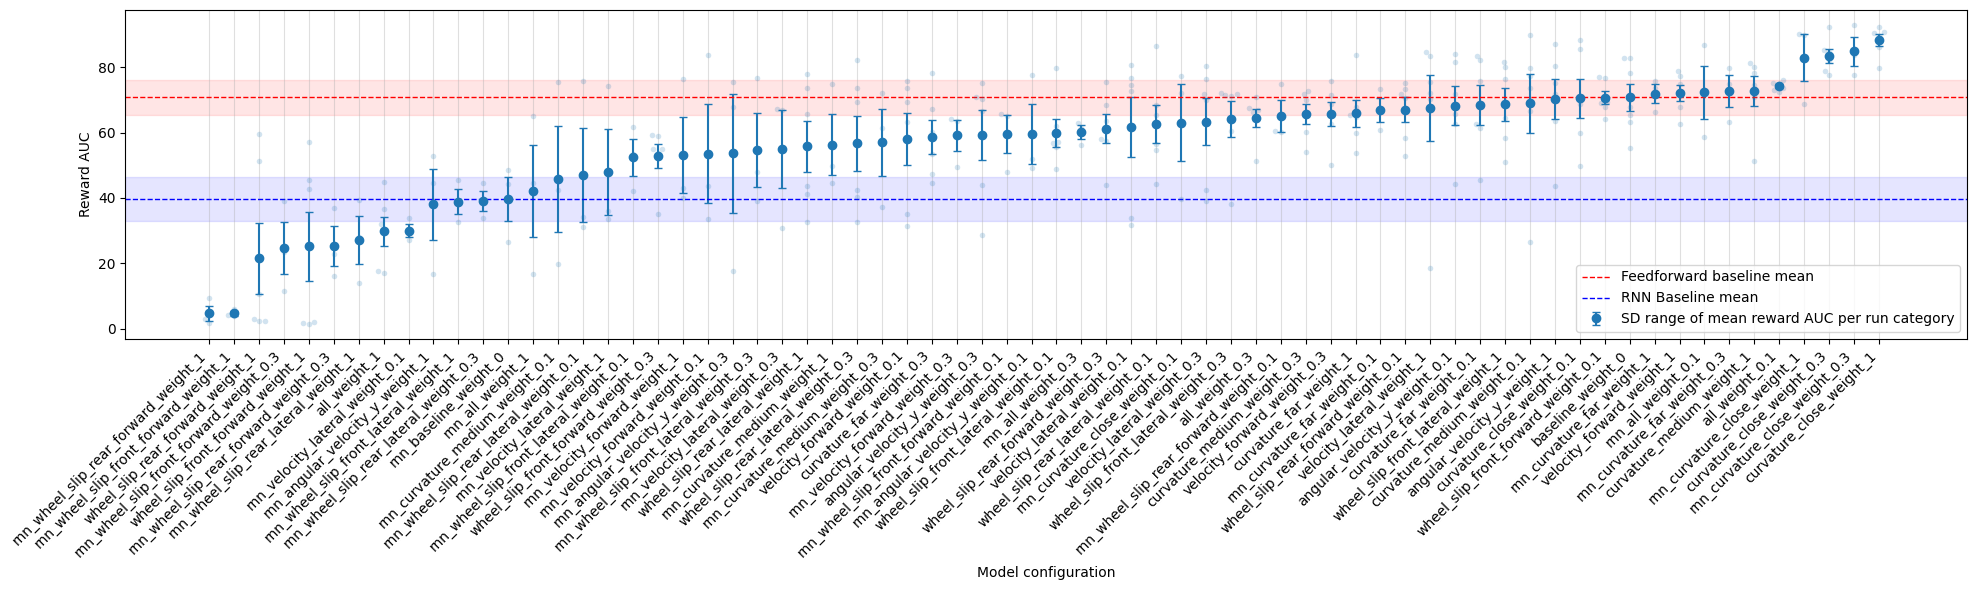

In [35]:
STAT = "reward/mean"

to_show = auc_df.sort_values(STAT)

to_show["label"] = to_show["run_category"] + \
    "_weight_" + to_show["aux_weight"].astype(str)

to_show_means = to_show.groupby(
    "label")[STAT].agg(["mean", "std", "sem"]).reset_index().sort_values("mean")

base_mean = to_show[to_show["run_category"] == "baseline"][STAT].mean()
base_std = to_show_means[to_show_means["label"].str.contains(
    "baseline")]["sem"].mean()
rnn_base_mean = to_show[to_show["run_category"] == "rnn_baseline"][STAT].mean()
rnn_base_std = to_show_means[to_show_means["label"].str.contains(
    "rnn_baseline")]["sem"].mean()

order = to_show_means["label"].tolist()

plt.figure(figsize=(20, 6))

plt.errorbar(
    to_show_means["label"],
    to_show_means["mean"],
    yerr=to_show_means["sem"],
    fmt="o",
    capsize=3,
    label="SD range of mean reward AUC per run category"
)
sns.swarmplot(
    data=to_show,
    x="label",
    y=STAT,
    order=order,
    legend=False,
    s=4,
    alpha=0.2
).set(xlabel="Model configuration", ylabel="Reward AUC")

sns.scatterplot(
    data=to_show_means,
    x="label",
    y="mean"
)

plt.grid(True, axis="x", alpha=0.4)

plt.axhline(base_mean, color="red", ls="--", lw=1, label="Feedforward baseline mean")

plt.axhspan(base_mean - base_std, base_mean + base_std,
            color="red", alpha=0.1)

plt.axhline(rnn_base_mean, color="blue", ls="--",
            lw=1, label="RNN Baseline mean")
plt.axhspan(rnn_base_mean - rnn_base_std, rnn_base_mean + rnn_base_std,
            color="blue", alpha=0.1)

plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/auc_comparison.pdf", bbox_inches="tight")

In [36]:
baseline = last_50_means.loc[last_50_means["run_category"] == "baseline", IMPORTANT_STATS]

last_50_means_ttest_results = (
    last_50_means[(last_50_means["run_category"] != "baseline") & (~last_50_means["run_category"].str.startswith("rnn_"))]
    .groupby(["run_category", "aux_weight"])[IMPORTANT_STATS]
    .apply(lambda g: pd.Series(ttest_ind(g, baseline, equal_var=False).pvalue, index=IMPORTANT_STATS))
)

last_50_means_ttest_results = pd.DataFrame(false_discovery_control(last_50_means_ttest_results), columns=last_50_means_ttest_results.columns, index=last_50_means_ttest_results.index)

In [37]:
ttest_ind(last_50_means.set_index(["run_category", "aux_weight"]).loc["curvature_close"].loc["1"]["collision/per_progress_metres"], last_50_means.set_index(["run_category", "aux_weight"]).loc["baseline"].loc["0"]["collision/per_progress_metres"])

TtestResult(statistic=np.float64(-1.795449304091608), pvalue=np.float64(0.10007264983064215), df=np.float64(11.0))

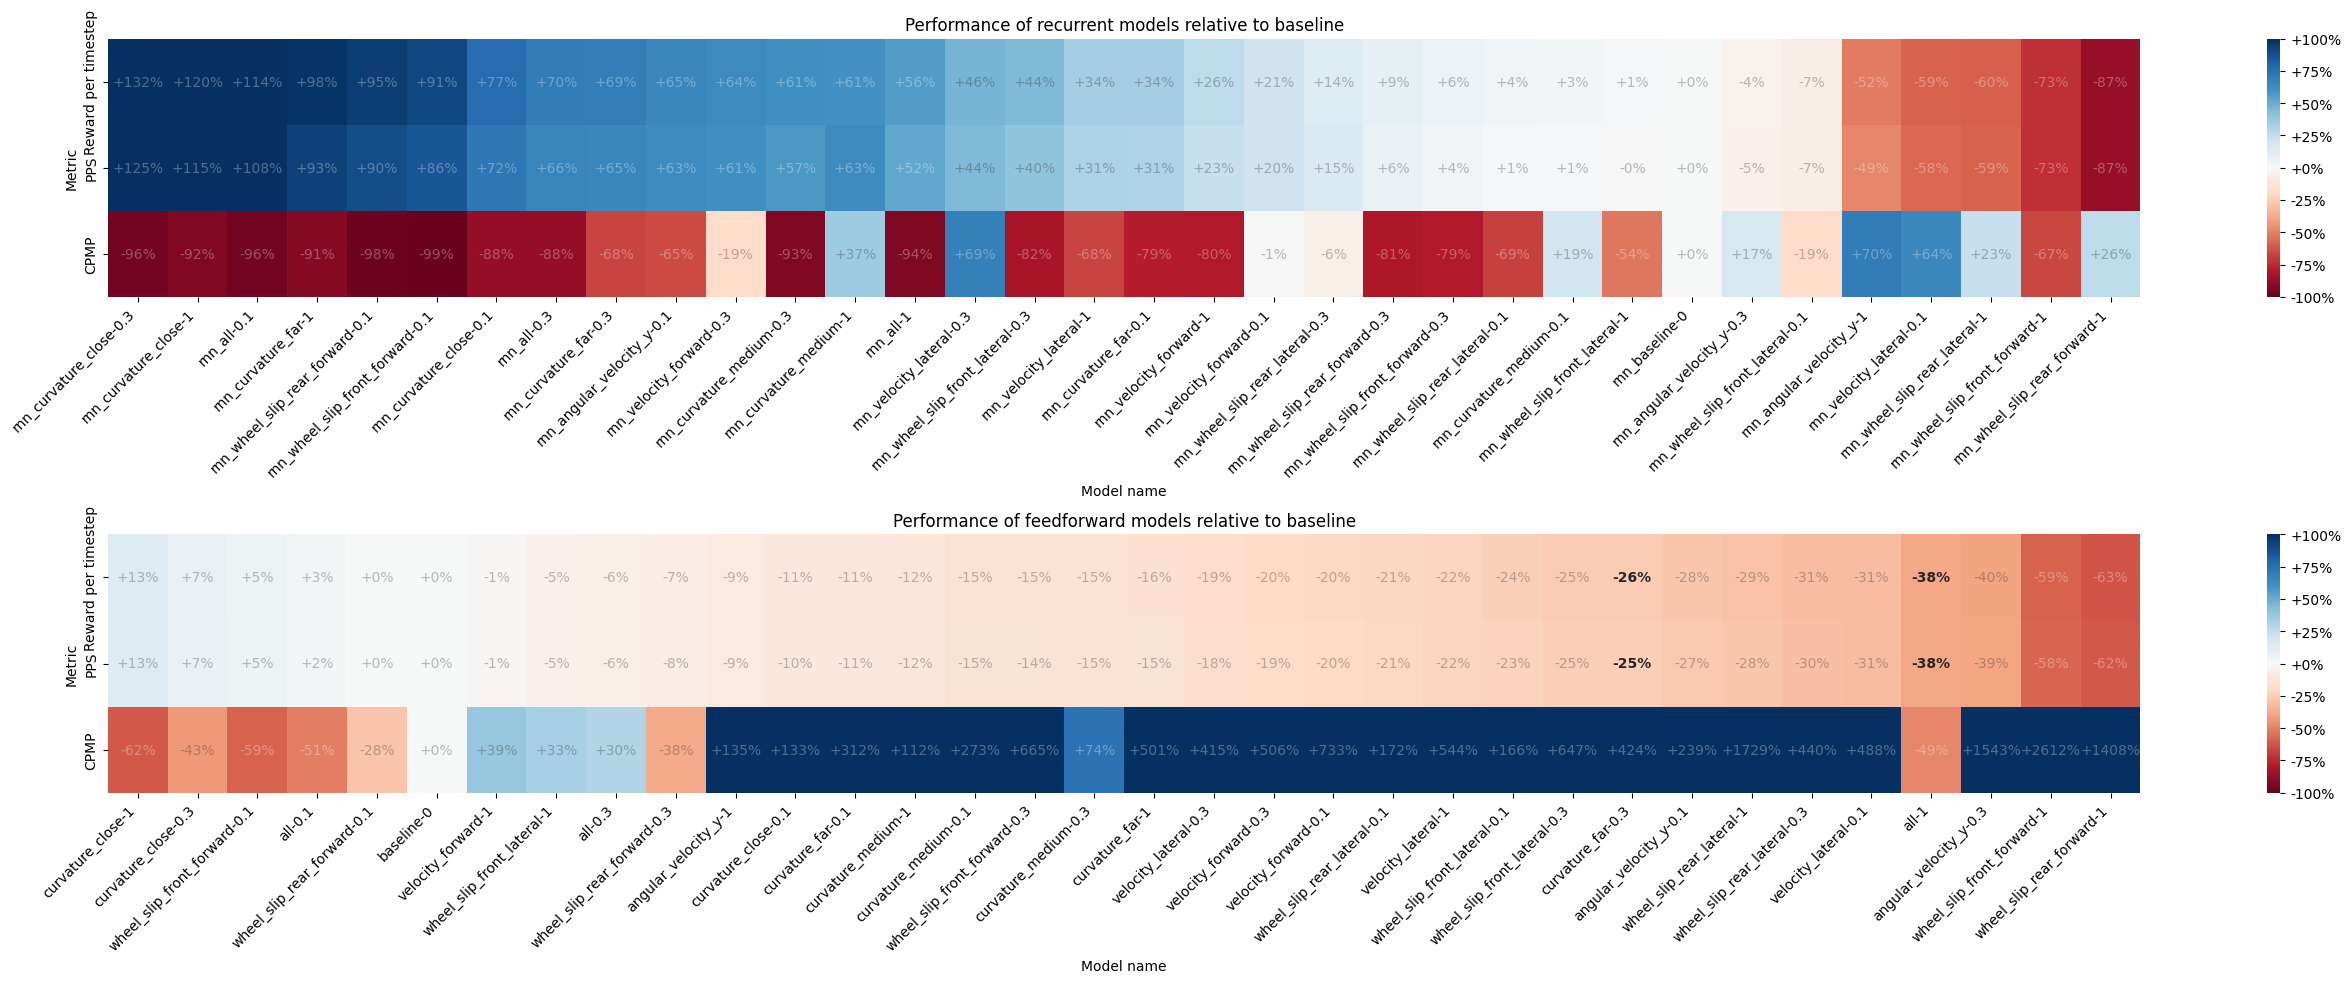

In [38]:
ALPHA = 0.1


def create_heatmap(ax, kind: Literal["recurrent", "feedforward"]):
    to_show = last_50_means[last_50_means["run_category"].str.startswith("rnn") if kind == "recurrent" else ~last_50_means["run_category"].str.startswith(
        "rnn")].groupby(["run_category", "aux_weight"])[MOST_IMPORTANT_STATS].mean().sort_values("reward/mean", ascending=False)

    baseline_name = "rnn_baseline" if kind == "recurrent" else "baseline"
    baseline_mean = to_show.loc[baseline_name].squeeze()
    baseline_runs = last_50_means.loc[last_50_means["run_category"] == baseline_name, MOST_IMPORTANT_STATS]
    baseline = to_show.loc["rnn_baseline" if kind ==
                           "recurrent" else "baseline"].squeeze()

    cat = last_50_means["run_category"]
    is_rnn = cat.str.startswith("rnn")
    in_kind = is_rnn if kind == "recurrent" else ~is_rnn

    to_test = last_50_means[in_kind & (cat != baseline_name)]

    last_50_means_ttest_results = (
        to_test
        .groupby(["run_category", "aux_weight"])[MOST_IMPORTANT_STATS]
        .apply(lambda g: pd.Series(ttest_ind(g, baseline_runs, equal_var=False).pvalue, index=MOST_IMPORTANT_STATS))
    )

    if last_50_means_ttest_results.isnull().values.any():
        raise ValueError("NaN values found in t-test results. Please check the input data for missing values.")
    last_50_means_ttest_results = pd.DataFrame(
        false_discovery_control(last_50_means_ttest_results.to_numpy().ravel()).reshape(last_50_means_ttest_results.shape),
        columns=last_50_means_ttest_results.columns, index=last_50_means_ttest_results.index)

    to_show = to_show.div(baseline, axis=1) - 1

    sig = (last_50_means_ttest_results < ALPHA).T.reindex(
        index=to_show.T.index, columns=to_show.T.columns, fill_value=False
    )

    ax = sns.heatmap(
        to_show.rename(columns=IMPORTANT_STATS_NAMES).T,
        annot=True,
        fmt="+.0%",
        cmap="RdBu",
        center=0,
        vmax=1.0,
        vmin=-1.0,
        cbar_kws={"format": FuncFormatter(lambda x, _: f"{x:+.0%}")},
        ax=ax
    )

    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set(xlabel="Model name", ylabel="Metric",
           title="Performance of " + kind + " models relative to baseline")
    # ax.xticks(rotation=45)

    for t in ax.texts:
        x, y = t.get_position()
        if sig.iat[int(y - 0.5), int(x - 0.5)]:
            t.set_fontweight("bold")
        else:
            t.set_alpha(0.3)


fig, axs = plt.subplots(2, 1, figsize=(30, 12))
fig.tight_layout(pad=15.0)

create_heatmap(axs[0], "recurrent")
create_heatmap(axs[1], "feedforward")

#plt.savefig("results/figures/last_50_means_heatmap.pdf", bbox_inches="tight")

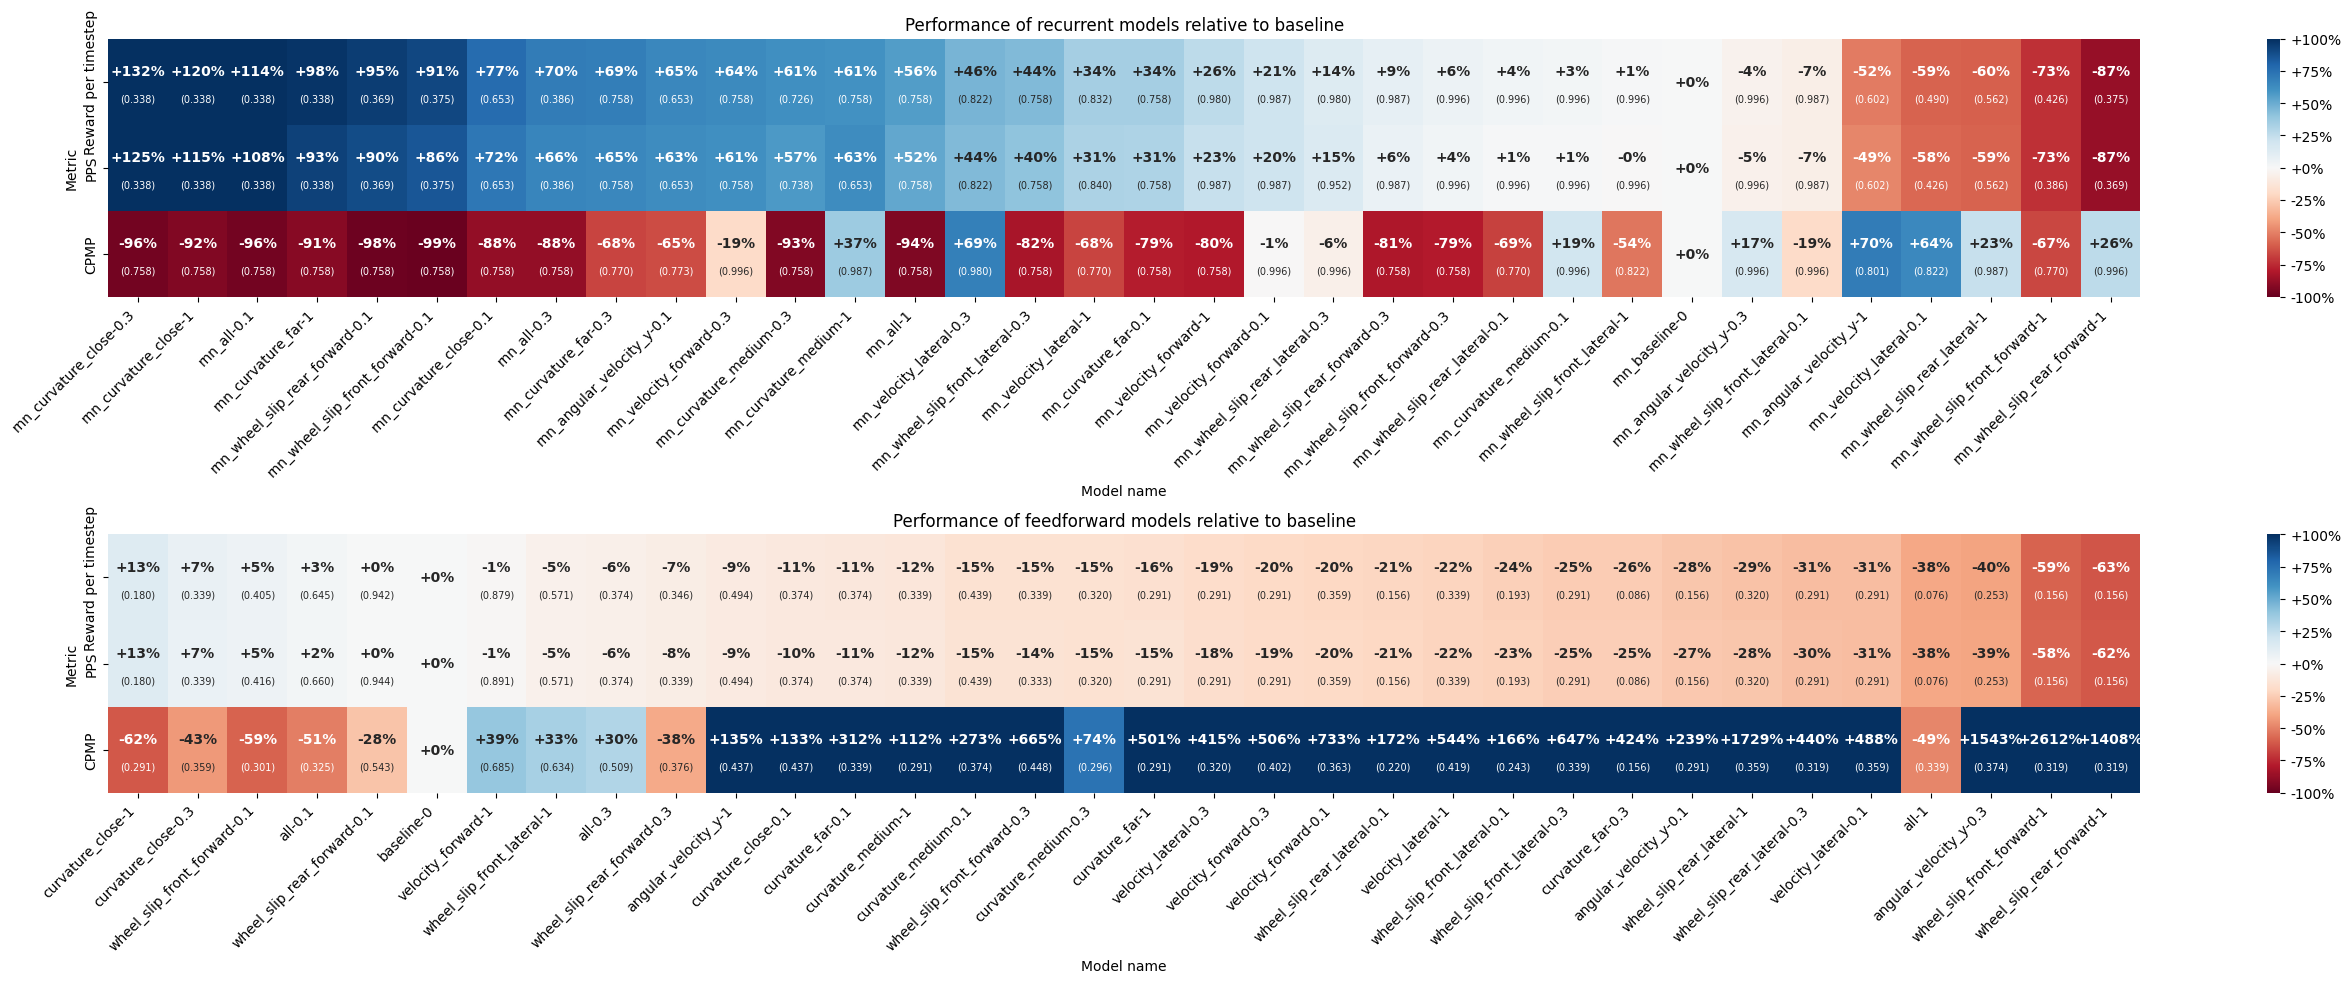

In [39]:
ALPHA = 0.1
P_SCALE = 0.7  # NEW: p-value font size relative to the main value


def create_heatmap(ax, kind: Literal["recurrent", "feedforward"]):
    to_show = last_50_means[last_50_means["run_category"].str.startswith("rnn") if kind == "recurrent" else ~last_50_means["run_category"].str.startswith(
        "rnn")].groupby(["run_category", "aux_weight"])[MOST_IMPORTANT_STATS].mean().sort_values("reward/mean", ascending=False)

    baseline_name = "rnn_baseline" if kind == "recurrent" else "baseline"
    baseline_mean = to_show.loc[baseline_name].squeeze()
    baseline_runs = last_50_means.loc[last_50_means["run_category"] == baseline_name, MOST_IMPORTANT_STATS]
    baseline = to_show.loc["rnn_baseline" if kind ==
                           "recurrent" else "baseline"].squeeze()

    cat = last_50_means["run_category"]
    is_rnn = cat.str.startswith("rnn")
    in_kind = is_rnn if kind == "recurrent" else ~is_rnn

    to_test = last_50_means[in_kind & (cat != baseline_name)]

    last_50_means_ttest_results = (
        to_test
        .groupby(["run_category", "aux_weight"])[MOST_IMPORTANT_STATS]
        .apply(lambda g: pd.Series(ttest_ind(g, baseline_runs, equal_var=False).pvalue, index=MOST_IMPORTANT_STATS))
    )

    if last_50_means_ttest_results.isnull().values.any():
        raise ValueError("NaN values found in t-test results. Please check the input data for missing values.")
    last_50_means_ttest_results = pd.DataFrame(
        false_discovery_control(last_50_means_ttest_results.to_numpy().ravel()).reshape(last_50_means_ttest_results.shape),
        columns=last_50_means_ttest_results.columns, index=last_50_means_ttest_results.index)

    to_show = to_show.div(baseline, axis=1) - 1

    sig = (last_50_means_ttest_results < ALPHA).T.reindex(
        index=to_show.T.index, columns=to_show.T.columns, fill_value=False
    )

    pvals = last_50_means_ttest_results.T.reindex(
        index=to_show.T.index, columns=to_show.T.columns
    )

    ax = sns.heatmap(
        to_show.rename(columns=IMPORTANT_STATS_NAMES).T,
        annot=True,
        fmt="+.0%",
        cmap="RdBu",
        center=0,
        vmax=1.0,
        vmin=-1.0,
        cbar_kws={"format": FuncFormatter(lambda x, _: f"{x:+.0%}")},
        ax=ax
    )

    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set(xlabel="Model name", ylabel="Metric",
           title="Performance of " + kind + " models relative to baseline")
    # ax.xticks(rotation=45)

    for t in list(ax.texts):
        x, y = t.get_position()
        i, j = int(y - 0.5), int(x - 0.5)
        
        t.set_fontweight("bold")

        p = pvals.iat[i, j]
        if pd.notna(p):
            t.set_position((x, y - 0.12)) 
            ax.text(
                x, y + 0.2, "(<0.001)" if p < 0.001 else f"({p:.3f})",
                ha="center", va="center",
                fontsize=t.get_fontsize() * P_SCALE,
                color=t.get_color()
            )


fig, axs = plt.subplots(2, 1, figsize=(30, 12))
fig.tight_layout(pad=15.0)

create_heatmap(axs[0], "recurrent")
create_heatmap(axs[1], "feedforward")

plt.savefig("results/figures/last_50_means_heatmap.pdf", bbox_inches="tight")

In [40]:
last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].agg(["mean", "std"]).loc["rnn_baseline"]

tag        reward/mean           observation/progress_per_second            \
                  mean       std                            mean       std   
aux_weight                                                                   
0             0.078021  0.029995                        2.007584  0.692739   

tag        observation/forward_velocity            \
                                   mean       std   
aux_weight                                          
0                              1.931944  0.659818   

tag        collision/per_progress_metres           collision/per_episode  \
                                    mean       std                  mean   
aux_weight                                                                 
0                               0.038162  0.049979               0.67429   

tag                  collision/per_step           observation/progress_metres  \
                 std               mean       std                        mean   
aux_weight                                                                      
0           0.236807           0.002186  0.002299                    0.080303   

tag                  
                std  
aux_weight           
0           0.02771

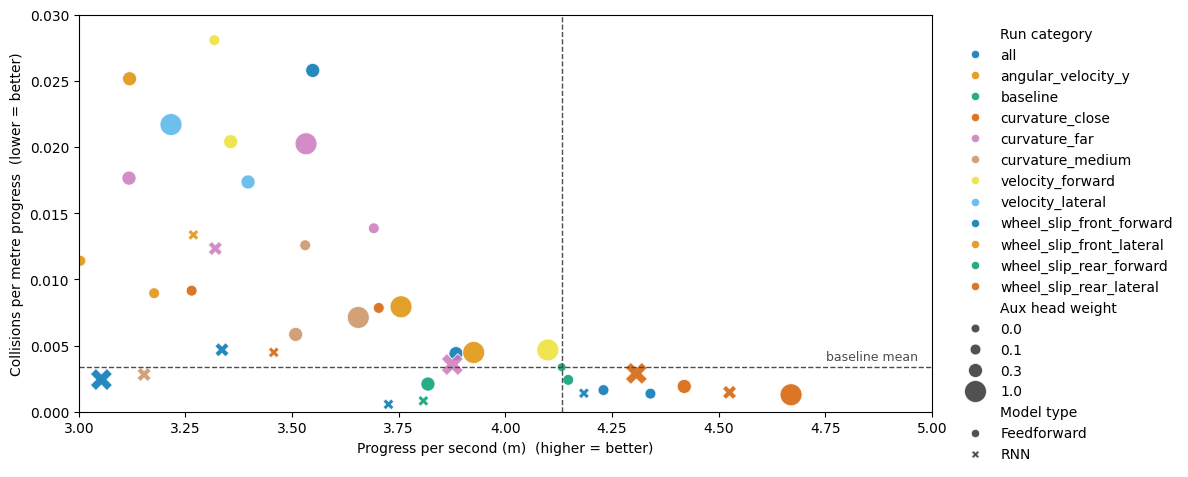

In [41]:
x_col = "observation/progress_per_second"
y_col = "collision/per_progress_metres"

cats = sorted(last_50_means["run_category"].unique())
palette = dict(zip(cats, sns.color_palette("colorblind", len(cats))))

to_show = (last_50_means
           .groupby(["run_category", "aux_weight"])[IMPORTANT_STATS]
           .mean().reset_index())

baseline = to_show[to_show["run_category"] == "baseline"]
bx, by = baseline[x_col].mean(), baseline[y_col].mean()

fig, ax = plt.subplots(figsize=(12, 5))
sns.scatterplot(
    data=to_show,
    x=x_col, y=y_col,
    style=to_show["run_category"].str.startswith("rnn_").map({True: "RNN", False: "Feedforward"}).rename("Model type"),
    hue=to_show["run_category"].str.lstrip("rnn_").rename("Run category"), 
    size=to_show["aux_weight"].astype(float).rename("Aux head weight"), 
    sizes=(40, 250),
    palette=palette, alpha=0.85, edgecolor="white", legend="full", ax=ax,
)

ax.axhline(by, color="0.3", ls="--", lw=1)
ax.axvline(bx, color="0.3", ls="--", lw=1)
ax.annotate("baseline mean", xy=(0.99, by), xycoords=("axes fraction", "data"),
            xytext=(-4, 5), textcoords="offset points",
            ha="right", fontsize=9, color="0.3")

ax.set(xlim=(3, 5), ylim=(0, 0.03),
       xlabel="Progress per second (m)  (higher = better)",
       ylabel="Collisions per metre progress  (lower = better)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig("results/figures/progress_vs_collision.pdf", bbox_inches="tight")

In [42]:
keys = ["run_category", "aux_weight"]

med = last_50_means.groupby(keys)["reward/mean"].transform("median")
dist = (last_50_means["reward/mean"] - med).abs()

median_rows = (
    last_50_means.assign(_dist=dist)
    .sort_values("_dist", kind="stable")
    .groupby(keys, as_index=False)
    .head(1)
    .drop(columns="_dist")
    .sort_values(keys)
    .reset_index(drop=True)
)
median_rows

tag,run_category,run_seed,aux_weight,reward/mean,observation/progress_per_second,observation/forward_velocity,collision/per_progress_metres,collision/per_episode,collision/per_step,observation/progress_metres
0,all,s2,0.1,0.168969,4.231395,3.974511,0.001539,0.229055,0.000260,0.169256
1,all,s3,0.3,0.153837,3.865749,3.696238,0.004621,0.507017,0.000715,0.154630
2,all,s4,1,0.090521,2.267021,2.107351,0.001597,0.133462,0.000145,0.090681
3,angular_velocity_y,s0,0.1,0.133512,3.359346,3.134266,0.006105,0.563055,0.000820,0.134374
4,angular_velocity_y,s5,0.3,0.112084,2.836902,2.664932,0.011933,0.700639,0.001354,0.113476
...,...,...,...,...,...,...,...,...,...,...
63,wheel_slip_rear_forward,s0,0.3,0.158650,3.975816,3.722913,0.002211,0.291382,0.000352,0.159033
64,wheel_slip_rear_forward,s5,1,0.012602,0.330054,0.323720,0.044875,0.458412,0.000592,0.013202
65,wheel_slip_rear_lateral,s0,0.1,0.127870,3.231728,3.027955,0.010450,0.669416,0.001351,0.129269
66,wheel_slip_rear_lateral,s2,0.3,0.098033,2.493258,2.366499,0.016483,0.741927,0.001644,0.099730


In [43]:
data_pivot["run_seed"]

0         s0
1         s0
2         s0
3         s1
4         s1
          ..
184106    s4
184107    s4
184108    s5
184109    s5
184110    s5
Name: run_seed, Length: 184111, dtype: object

<Axes: xlabel='collision/per_progress_metres', ylabel='observation/progress_per_second'>

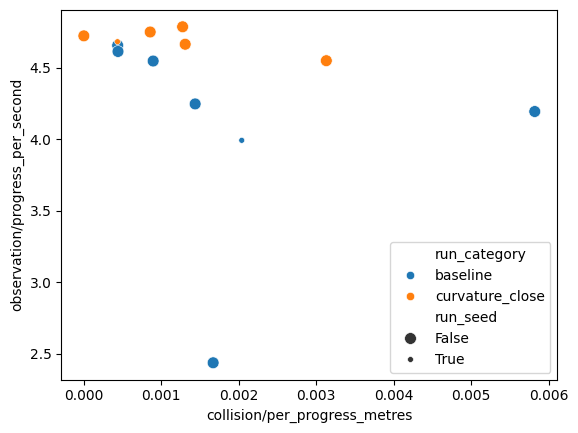

In [44]:
to_show = data_pivot[(data_pivot["run_category"].isin(["baseline", "curvature_close"])) & (data_pivot["step"] == 599.0) & (data_pivot["aux_weight"].isin(["0", "1"]))]

sns.scatterplot(
    data=to_show,
    hue="run_category",
    x="collision/per_progress_metres",
    size=to_show["run_seed"].isin(["s2"]),
    y="observation/progress_per_second"
)

In [45]:
last_50_means

tag,run_category,run_seed,aux_weight,reward/mean,observation/progress_per_second,observation/forward_velocity,collision/per_progress_metres,collision/per_episode,collision/per_step,observation/progress_metres
0,all,s0,0.1,0.175062,4.382294,4.091511,0.001133,0.193132,0.000199,0.175292
1,all,s0,0.3,0.162019,4.061126,3.783238,0.002485,0.312783,0.000404,0.162445
2,all,s0,1,0.103041,2.577936,2.365458,0.000663,0.075912,0.000068,0.103117
3,all,s1,0.1,0.161085,4.033868,3.768374,0.001503,0.224590,0.000243,0.161355
4,all,s1,0.3,0.171508,4.296201,4.017535,0.001828,0.265081,0.000314,0.171848
...,...,...,...,...,...,...,...,...,...,...
302,wheel_slip_rear_lateral,s4,0.3,0.067599,1.779842,1.716670,0.048992,0.929794,0.003488,0.071194
303,wheel_slip_rear_lateral,s4,1,0.170777,4.281844,4.050769,0.002575,0.345189,0.000441,0.171274
304,wheel_slip_rear_lateral,s5,0.1,0.095827,2.427968,2.277983,0.013005,0.688965,0.001263,0.097119
305,wheel_slip_rear_lateral,s5,0.3,0.147494,3.700960,3.530883,0.003353,0.393763,0.000496,0.148038


<Axes: xlabel='collision/per_progress_metres', ylabel='observation/progress_per_second'>

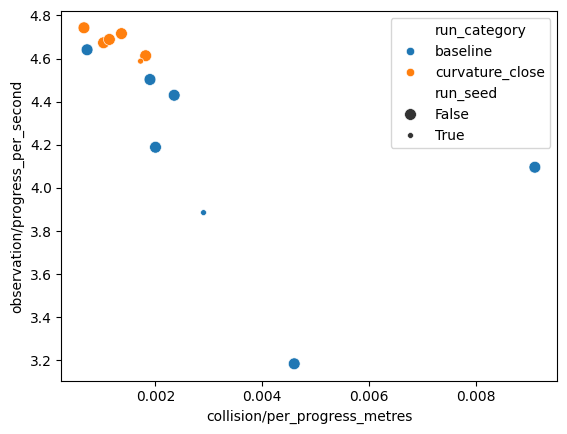

In [46]:
to_show = last_50_means[(last_50_means["run_category"].isin(["baseline", "curvature_close"])) & (last_50_means["aux_weight"].isin(["0", "1"]))]

sns.scatterplot(
    data=to_show,
    hue="run_category",
    x="collision/per_progress_metres",
    size=to_show["run_seed"].isin(["s2"]),
    y="observation/progress_per_second"
)

In [47]:
to_show = data_pivot[
    data_pivot["run_category"].isin(["baseline","rnn_baseline"])
    | (
        (data_pivot["run_category"] == "rnn_curvature_close")
        & (data_pivot["aux_weight"] == "0.3")
    ) | (
        (data_pivot["run_category"] == "curvature_close")
                & (data_pivot["aux_weight"] == "1")
    )
].copy()


to_show["Run category"] = np.where(to_show["run_category"].str.contains(
    "baseline"), to_show["run_category"], to_show["run_category"] + "_" + to_show["aux_weight"])
to_show

tag,step,run_category,run_seed,aux_weight,collision/per_episode,collision/per_step,observation/forward_velocity,observation/progress_metres,reward/mean,collision/per_progress_metres,observation/progress_per_second,Run category
36,0.0,baseline,s0,0,1.000000,0.000977,0.058663,0.002326,0.001346,0.419758,0.058162,baseline
37,0.0,baseline,s1,0,1.000000,0.001383,-0.024031,-0.000907,-0.002278,-1.524610,-0.022686,baseline
38,0.0,baseline,s2,0,1.000000,0.000651,0.004044,0.000103,-0.000545,6.320993,0.002575,baseline
39,0.0,baseline,s3,0,1.000000,0.000977,0.020375,0.000804,-0.000175,1.214709,0.020099,baseline
40,0.0,baseline,s4,0,1.000000,0.000570,0.027750,0.001074,0.000500,0.530256,0.026858,baseline
...,...,...,...,...,...,...,...,...,...,...,...,...
183920,599.0,rnn_baseline,s2,0,0.924528,0.003988,1.003005,0.040878,0.036742,0.097550,1.021945,rnn_baseline
183921,599.0,rnn_baseline,s3,0,0.933333,0.003418,1.726816,0.074350,0.070510,0.045971,1.858759,rnn_baseline
183923,599.0,rnn_curvature_close,s1,0.3,0.076923,0.000081,4.223042,0.181345,0.181262,0.000449,4.533613,rnn_curvature_close_0.3
183926,599.0,rnn_curvature_close,s2,0.3,0.043478,0.000081,4.264378,0.183779,0.183683,0.000443,4.594481,rnn_curvature_close_0.3


In [48]:
data_pivot["aux_weight"].value_counts()

aux_weight
0.3    59378
0.1    59377
1      59367
0       5989
Name: count, dtype: int64

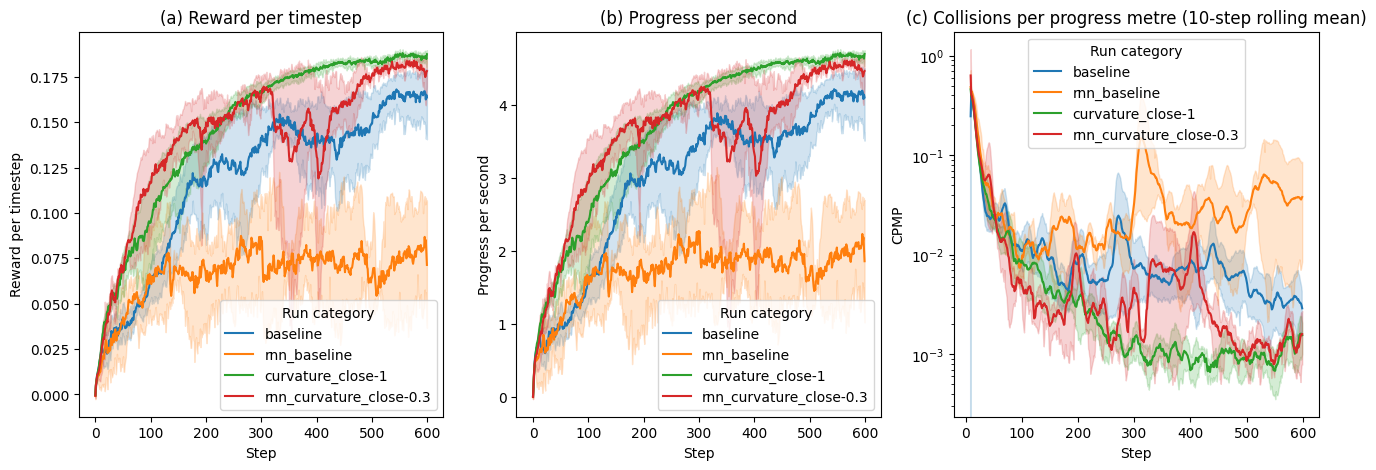

In [49]:
to_show = data_pivot[
    data_pivot["run_category"].isin(["baseline","rnn_baseline"])
    | (
        (data_pivot["run_category"] == "rnn_curvature_close")
        & (data_pivot["aux_weight"] == "0.3")
    ) | (
        (data_pivot["run_category"] == "curvature_close")
                & (data_pivot["aux_weight"] == "1")
    )
].copy()


to_show["Run category"] = np.where(to_show["run_category"].str.contains(
    "baseline"), to_show["run_category"], to_show["run_category"] + "-" + to_show["aux_weight"])
hue_order = ["baseline", "rnn_baseline", "curvature_close-1", "rnn_curvature_close-0.3"]
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
sns.lineplot(
    data=to_show.rename(
        columns={"step": "Step", "reward/mean": "Reward per timestep"}),
    hue="Run category",
    x="Step",
    y="Reward per timestep",
    ax=axs[0],
    hue_order=hue_order
).set(title="(a) Reward per timestep")

sns.lineplot(
    data=to_show.rename(columns={
                        "step": "Step", "observation/progress_per_second": "Progress per second"}),
    hue="Run category",
    x="Step",
    y="Progress per second",
    ax=axs[1],
    hue_order=hue_order,
).set(title="(b) Progress per second")

sns.lineplot(
    data=to_show.rename(columns={"step": "Step", "collision/per_progress_metres": "CPMP"}).groupby(
        ["Run category", "run_seed"]).rolling(10, on="Step")["CPMP"].mean().reset_index(),
    hue="Run category",
    x="Step",
    y="CPMP",
    ax=axs[2],
    hue_order=hue_order,
).set(yscale="log", title="(c) Collisions per progress metre (10-step rolling mean)")

plt.savefig("results/figures/training_perf.pdf", bbox_inches="tight")

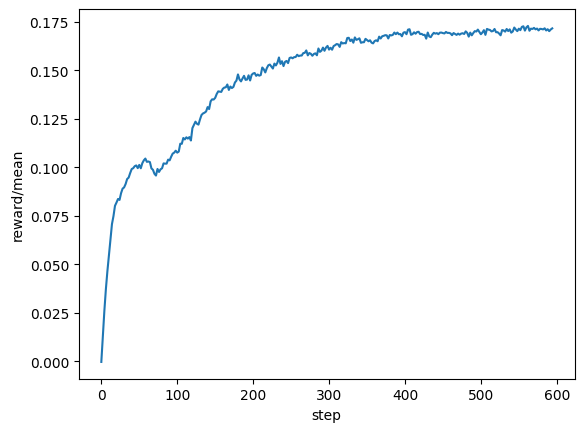

In [50]:
baseline = load_runs(logdir="runs_old").pivot_table(index="step", columns="tag", values="value").reset_index()
sns.lineplot(baseline * 2, x="step", y="reward/mean")
plt.savefig("results/figures/baseline_reward.pdf")